# 1 · Predição: risco de míldio na vinha
**AgroNet Forward · AI Insights for Agro**

**Pergunta de negócio:** *com base na meteorologia, vale a pena reforçar a vigilância ou o tratamento hoje?*

Neste notebook vamos:
1. olhar para os dados e perceber o problema;
2. construir uma previsão com um modelo **simples e leve** (*random forest*);
3. avaliá-la **em termos de negócio** (falsos alarmes vs. doença não prevenida);
4. perceber o que o modelo "olha" e o que fazer com dados reais.

> ⚠️ **Dados sintéticos.** Foram simulados para fins didáticos, inspirados na lógica agronómica
> (chuva, humidade e molhamento foliar favorecem a infeção). Não representam nenhuma vinha real e o
> modelo **não deve ser usado para decisões de tratamento**.

> 💡 **No Google Colab:** *Ficheiro → Carregar para a sessão* e carregue o CSV desta pasta `dados/`. Se não o fizer, o notebook gera automaticamente os mesmos dados.

## 0 · Preparação

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score)
from sklearn.inspection import permutation_importance

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

# --- Gerador de reserva -------------------------------------------
# Se o ficheiro CSV não estiver na pasta (p.ex. no Google Colab), os dados
# são gerados aqui, com a mesma semente => exatamente os mesmos dados.
# (Pode ignorar este código; o notebook começa na secção 1.)

def gerar_meteo(seed=42, anos=(2020, 2021, 2022, 2023, 2024)):
    rng = np.random.default_rng(seed)
    blocos = []
    for ano in anos:
        datas = pd.date_range(f"{ano}-04-01", f"{ano}-09-30", freq="D")
        n = len(datas)
        dia = np.arange(n)
        # Temperatura média: sazonalidade (pico em finais de julho) + ruído autocorrelacionado
        base = 19 + 7 * np.sin((dia - 45) / n * np.pi)
        ruido = np.zeros(n)
        for i in range(1, n):
            ruido[i] = 0.7 * ruido[i - 1] + rng.normal(0, 1.8)
        # Variabilidade interanual (anos mais quentes/frescos)
        t_med = base + ruido + rng.normal(0, 1.0)
        amplitude = rng.uniform(9, 15, n)
        t_max = t_med + amplitude / 2
        t_min = t_med - amplitude / 2

        # Precipitação: mais frequente na primavera, rara no verão
        p_chuva = 0.34 - 0.24 * np.sin(dia / n * np.pi)
        chove = rng.random(n) < p_chuva
        # chuva persiste um pouco (sistemas frontais)
        for i in range(1, n):
            if chove[i - 1] and rng.random() < 0.25:
                chove[i] = True
        precip = np.where(chove, rng.gamma(1.2, 4.5, n), 0.0)

        # Humidade relativa: sobe com chuva, desce com calor
        hum = 72 - 1.1 * (t_med - 19) + np.where(chove, 14, 0) + rng.normal(0, 6, n)
        hum = np.clip(hum, 25, 99)

        # Molhamento foliar (h): depende de chuva e humidade
        molh = np.where(chove, rng.uniform(5, 14, n), np.clip((hum - 78) / 3, 0, 8) + rng.normal(0, 1, n))
        molh = np.clip(molh, 0, 24)

        vento = np.clip(rng.gamma(3, 4, n), 0, 60)

        df = pd.DataFrame({
            "data": datas,
            "temp_media": t_med.round(1),
            "temp_max": t_max.round(1),
            "temp_min": t_min.round(1),
            "precip_mm": precip.round(1),
            "humidade_rel": hum.round(0),
            "molhamento_h": molh.round(1),
            "vento_kmh": vento.round(0),
        })

        # Risco (simulado): condições favoráveis de infeção nos 2-3 dias anteriores
        chuva_48h = pd.Series(precip).rolling(2, min_periods=1).sum().to_numpy()
        hum_3d = pd.Series(hum).rolling(3, min_periods=1).mean().to_numpy()
        molh_3d = pd.Series(molh).rolling(3, min_periods=1).mean().to_numpy()
        score = (
            -2.6
            + 1.5 * (chuva_48h > 5)
            + 0.05 * (hum_3d - 60)
            + 0.15 * molh_3d
            - 0.02 * (t_med - 20) ** 2
        )
        prob = 1 / (1 + np.exp(-score))
        df["risco_miledio"] = (rng.random(n) < prob).astype(int)
        blocos.append(df)
    return pd.concat(blocos, ignore_index=True)

## 1 · Os dados

In [2]:
CAMINHO = "../dados/meteo_miledio.csv"
if os.path.exists(CAMINHO):
    df = pd.read_csv(CAMINHO, parse_dates=["data"])
else:
    print("CSV não encontrado -> a gerar os dados na hora.")
    df = gerar_meteo()

print(df.shape)
df.head()

(915, 9)


,data,temp_media,temp_max,temp_min,precip_mm,humidade_rel,molhamento_h,vento_kmh,risco_miledio
0,2020-04-01,13.7,19.3,8.1,0.0,81.0,2.7,16.0,0
1,2020-04-02,14.3,19.1,9.6,0.0,70.0,0.0,7.0,0
2,2020-04-03,12.4,19.1,5.7,1.2,89.0,11.8,22.0,0
3,2020-04-04,14.3,19.6,9.0,0.4,99.0,9.5,9.0,1
4,2020-04-05,16.0,23.3,8.7,11.8,86.0,11.8,2.0,1


Cada linha é **um dia** (1 abril – 30 setembro, cinco épocas). A coluna **`risco_miledio`** é o que
queremos prever: `1` = dia de risco, `0` = sem risco.

Repare no equilíbrio das classes: os dias de risco são **a minoria**. Isto importa muito mais do
que parece, como vamos ver.

In [3]:
print("Percentagem de dias de risco:", f"{df.risco_miledio.mean():.1%}")
print()
print("Por mês (% de dias de risco):")
print((df.groupby(df.data.dt.month).risco_miledio.mean() * 100).round(0).astype(int).to_string())

Percentagem de dias de risco: 18.6%

Por mês (% de dias de risco):
data
4    25
5    25
6    18
7    10
8    13
9    21


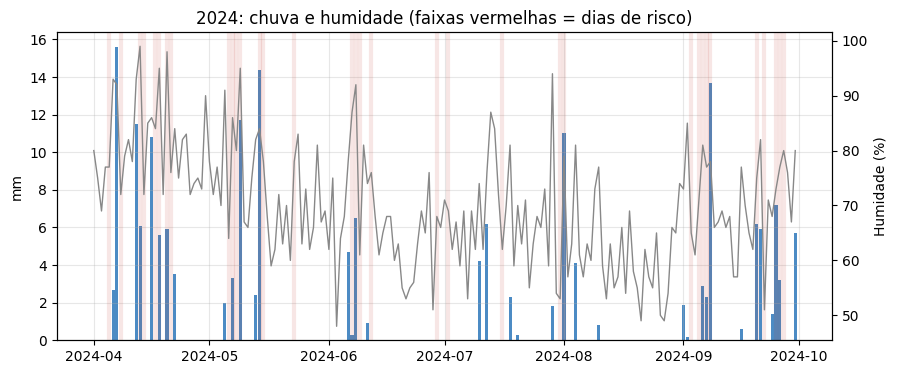

In [4]:
ano = df[df.data.dt.year == 2024]
fig, ax = plt.subplots()
ax.bar(ano.data, ano.precip_mm, color="#4C8BC4", label="Precipitação (mm)")
ax.set_ylabel("mm")
ax2 = ax.twinx()
ax2.plot(ano.data, ano.humidade_rel, color="#888", lw=1, label="Humidade (%)")
ax2.set_ylabel("Humidade (%)")
ax2.grid(False)
for d in ano.data[ano.risco_miledio == 1]:
    ax.axvline(d, color="#C0392B", alpha=0.12, lw=3)
ax.set_title("2024: chuva e humidade (faixas vermelhas = dias de risco)")
plt.show()

## 2 · Preparar as variáveis ("features")
O risco de hoje não depende só do tempo de hoje: **o que choveu nos últimos dias** conta.
Por isso criamos variáveis com **janelas de dias anteriores**. Usamos apenas informação do passado
e do próprio dia, que em produção viria das medições e da previsão meteorológica.

In [5]:
df = df.sort_values("data").reset_index(drop=True)
df["ano"] = df.data.dt.year
g = df.groupby("ano")  # janelas dentro de cada época, sem misturar anos

df["chuva_48h"] = g["precip_mm"].transform(lambda s: s.rolling(2, min_periods=1).sum())
df["chuva_7d"]  = g["precip_mm"].transform(lambda s: s.rolling(7, min_periods=1).sum())
df["hum_3d"]    = g["humidade_rel"].transform(lambda s: s.rolling(3, min_periods=1).mean())
df["molh_3d"]   = g["molhamento_h"].transform(lambda s: s.rolling(3, min_periods=1).mean())
df["temp_3d"]   = g["temp_media"].transform(lambda s: s.rolling(3, min_periods=1).mean())
df["mes"]       = df.data.dt.month

FEATURES = ["temp_media", "temp_max", "temp_min", "precip_mm", "humidade_rel",
            "molhamento_h", "vento_kmh", "chuva_48h", "chuva_7d", "hum_3d",
            "molh_3d", "temp_3d", "mes"]
df[FEATURES].describe().round(1).T[["mean", "min", "max"]]

,mean,min,max
temp_media,22.0,8.3,35.5
temp_max,28.0,14.4,41.0
temp_min,16.1,1.1,30.0
precip_mm,1.2,0.0,28.6
humidade_rel,71.9,45.0,99.0
molhamento_h,2.5,0.0,14.0
vento_kmh,11.9,1.0,48.0
chuva_48h,2.4,0.0,36.1
chuva_7d,8.1,0.0,41.0
hum_3d,72.0,51.0,97.3


## 3 · Treino e teste — **separar no tempo**
Treinamos com as épocas **2020–2023** e testamos em **2024**, que o modelo nunca viu.

> 🔑 Em dados temporais **não se baralham os dias** ao acaso: o modelo teria "espreitado" o futuro
> e os resultados ficariam otimistas. Testar numa época nova imita o uso real.

In [6]:
treino = df[df.ano < 2024]
teste  = df[df.ano == 2024]
X_tr, y_tr = treino[FEATURES], treino.risco_miledio
X_te, y_te = teste[FEATURES],  teste.risco_miledio
print(f"Treino: {len(treino)} dias | Teste: {len(teste)} dias | dias de risco no teste: {int(y_te.sum())}")

Treino: 732 dias | Teste: 183 dias | dias de risco no teste: 34


### 3.1 · Antes do modelo: quais são as referências ("baselines")?
Um modelo só é útil se **bater soluções simples**. Duas referências:
- **"Nunca há risco"** (não fazer nada);
- **Regra manual**: "choveu mais de 5 mm nas últimas 48 h".

In [7]:
def metricas(y, pred, nome):
    tp = int(((pred == 1) & (y == 1)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec  = tp / (tp + fn) if tp + fn else 0.0
    f1   = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return {"método": nome, "exatidão": round((tp + tn) / len(y), 3),
            "dias de risco apanhados (recall)": round(rec, 2),
            "alarmes certos (precisão)": round(prec, 2), "F1": round(f1, 2),
            "falsos alarmes": fp, "riscos falhados": fn}

res = [metricas(y_te, np.zeros(len(y_te), dtype=int), "Nunca há risco"),
       metricas(y_te, (teste.chuva_48h > 5).astype(int), "Regra: chuva 48h > 5 mm")]
pd.DataFrame(res).set_index("método")

,exatidão,dias de risco apanhados (recall),alarmes certos (precisão),F1,falsos alarmes,riscos falhados
método,,,,,,
Nunca há risco,0.814,0.00,0.00,0.00,0,34
Regra: chuva 48h > 5 mm,0.858,0.56,0.63,0.59,11,15


Repare: **"nunca há risco" tem uma exatidão (*accuracy*) altíssima e é completamente inútil** (apanha 0% dos
riscos). Com classes desequilibradas, a exatidão engana. Por isso olhamos para *recall* (quantos riscos
apanhei) e *precisão* (quantos alarmes eram verdadeiros).

### 3.2 · O modelo

In [8]:
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced",
                            random_state=0, n_jobs=-1).fit(X_tr, y_tr)
hgb = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.08, random_state=0).fit(X_tr, y_tr)

prob_rf  = rf.predict_proba(X_te)[:, 1]
prob_hgb = hgb.predict_proba(X_te)[:, 1]

res += [metricas(y_te, (prob_rf >= 0.5).astype(int), "Random forest"),
        metricas(y_te, (prob_hgb >= 0.5).astype(int), "Gradient boosting")]
tabela = pd.DataFrame(res).set_index("método")
print("AUC (random forest):", round(roc_auc_score(y_te, prob_rf), 3),
      "| AUC (gradient boosting):", round(roc_auc_score(y_te, prob_hgb), 3))
tabela

AUC (random forest): 0.83 | AUC (gradient boosting): 0.826


,exatidão,dias de risco apanhados (recall),alarmes certos (precisão),F1,falsos alarmes,riscos falhados
método,,,,,,
Nunca há risco,0.814,0.00,0.00,0.00,0,34
Regra: chuva 48h > 5 mm,0.858,0.56,0.63,0.59,11,15
Random forest,0.852,0.47,0.64,0.54,9,18
Gradient boosting,0.869,0.44,0.75,0.56,5,19


> 🔍 **Leitura honesta:** com o limiar "por defeito" (0,5), o modelo **não é claramente melhor** do que a regra manual
> (a regra apanha mais riscos; o modelo tem menos falsos alarmes). O valor do modelo não está em "ganhar por KO",
> mas em **dar uma probabilidade** que permite **ajustar a decisão ao custo real** de errar (secção 4).

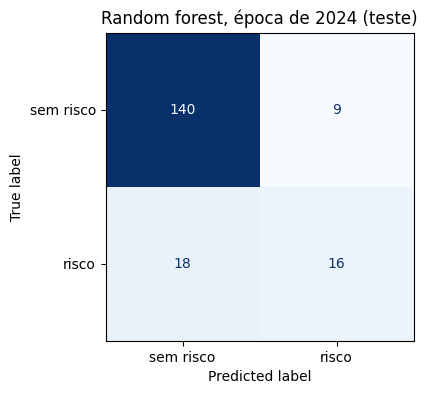

In [9]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_te, (prob_rf >= 0.5).astype(int)),
                       display_labels=["sem risco", "risco"]).plot(ax=ax, colorbar=False, cmap="Blues")
ax.set_title("Random forest, época de 2024 (teste)")
ax.grid(False)
plt.show()

## 4 · O limiar de decisão é uma decisão **de negócio**
O modelo devolve uma **probabilidade**. Decidimos "tratar" a partir de que valor? Depende do que custa
errar em cada sentido:

- **falso alarme** = tratamento/vigilância desnecessária;
- **risco falhado** = infeção que podia ter sido evitada.

Os custos abaixo são **ilustrativos**. Altere-os e veja como muda o melhor limiar!

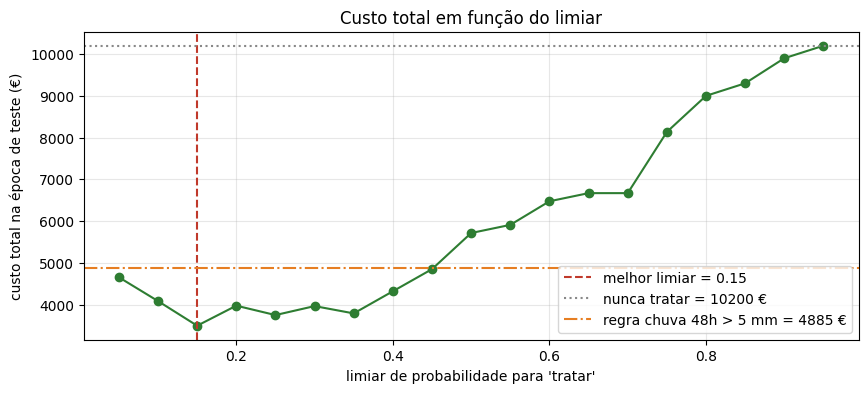

Modelo com limiar 0.15: 3495 €  |  regra manual: 4885 €  |  nunca tratar: 10200 €  |  tratar sempre: 5215 €


In [10]:
CUSTO_FALSO_ALARME = 35    # € por tratamento desnecessário (ilustrativo)
CUSTO_RISCO_FALHADO = 300  # € por episódio de infeção não prevenido (ilustrativo)

limiares = np.round(np.arange(0.05, 0.96, 0.05), 2)
custos = []
for l in limiares:
    pred = prob_rf >= l
    fp = int(((pred == 1) & (y_te == 0)).sum())
    fn = int(((pred == 0) & (y_te == 1)).sum())
    custos.append(fp * CUSTO_FALSO_ALARME + fn * CUSTO_RISCO_FALHADO)

melhor = limiares[int(np.argmin(custos))]
custo_nunca = int(y_te.sum()) * CUSTO_RISCO_FALHADO
custo_sempre = int((y_te == 0).sum()) * CUSTO_FALSO_ALARME
regra = (teste.chuva_48h > 5).astype(int)
custo_regra = (int(((regra == 1) & (y_te == 0)).sum()) * CUSTO_FALSO_ALARME
               + int(((regra == 0) & (y_te == 1)).sum()) * CUSTO_RISCO_FALHADO)

fig, ax = plt.subplots()
ax.plot(limiares, custos, marker="o", color="#2E7D32")
ax.axvline(melhor, color="#C0392B", ls="--", label=f"melhor limiar = {melhor}")
ax.axhline(custo_nunca, color="#888", ls=":", label=f"nunca tratar = {custo_nunca} €")
ax.axhline(custo_regra, color="#E67E22", ls="-.", label=f"regra chuva 48h > 5 mm = {custo_regra} €")
ax.set_xlabel("limiar de probabilidade para 'tratar'")
ax.set_ylabel("custo total na época de teste (€)")
ax.legend()
ax.set_title("Custo total em função do limiar")
plt.show()

print(f"Modelo com limiar {melhor}: {min(custos)} €  |  regra manual: {custo_regra} €  |  "
      f"nunca tratar: {custo_nunca} €  |  tratar sempre: {custo_sempre} €")

## 5 · O que é que o modelo está a "olhar"?
A **importância por permutação** baralha uma variável de cada vez e mede quanto o modelo piora.
Quanto mais piora, mais essa variável contava.

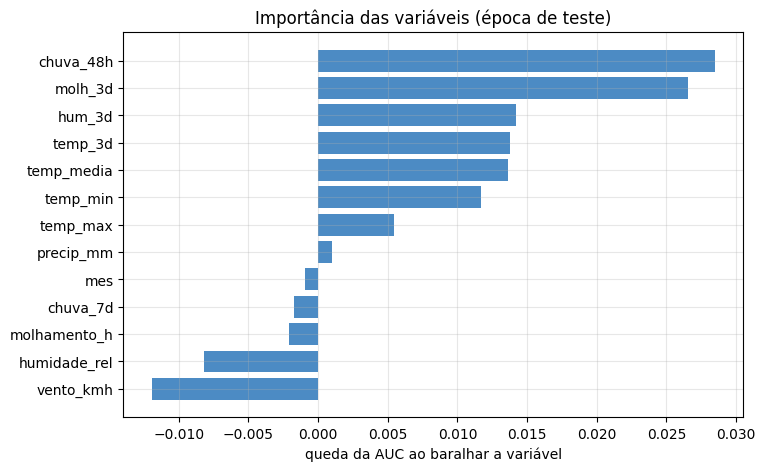

In [11]:
imp = permutation_importance(rf, X_te, y_te, n_repeats=10, scoring="roc_auc",
                             random_state=0, n_jobs=-1)
ordem = np.argsort(imp.importances_mean)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(np.array(FEATURES)[ordem], imp.importances_mean[ordem], color="#4C8BC4")
ax.set_xlabel("queda da AUC ao baralhar a variável")
ax.set_title("Importância das variáveis (época de teste)")
plt.show()

## 6 · Exercícios para experimentar
1. **Altere os custos** (célula do limiar): e se uma infeção custar 1 000 €? E se tratar custar 120 €?
2. **Retire variáveis**: remova `molhamento_h`, `molh_3d` (nem toda a gente tem sensor de molhamento) e
   volte a treinar. Quanto perde o modelo?
3. **Acrescente uma variável**: por exemplo `df["amplitude"] = df.temp_max - df.temp_min`.
4. **Teste com menos dados**: treine só com 2023 (`df.ano == 2023`). O que acontece?

## 7 · E com dados reais?
O que torna o exercício real **não é o algoritmo, são os dados**:
- **Meteorologia**: gratuita e fácil de obter (ver célula seguinte, opcional).
- **Rótulos**: o difícil. É preciso o **registo de ocorrências reais** (datas de aparecimento de míldio, tratamentos)
  da *vossa* vinha. Sem rótulos fiáveis, não há modelo; comecem a registar já.

In [ ]:
# OPCIONAL — requer internet (no Colab funciona). Obtém meteorologia real da API gratuita Open-Meteo
# para a zona do Peso da Régua. Serve para ver como é fácil obter os dados de entrada.
import requests

url = "https://archive-api.open-meteo.com/v1/archive"
params = {
    "latitude": 41.16, "longitude": -7.79,
    "start_date": "2024-04-01", "end_date": "2024-09-30",
    "daily": ("temperature_2m_mean,temperature_2m_max,temperature_2m_min,"
              "precipitation_sum,relative_humidity_2m_mean,wind_speed_10m_max"),
    "timezone": "Europe/Lisbon",
}
try:
    r = requests.get(url, params=params, timeout=20)
    r.raise_for_status()
    d = r.json()["daily"]
    real = pd.DataFrame({
        "data": pd.to_datetime(d["time"]),
        "temp_media": d["temperature_2m_mean"], "temp_max": d["temperature_2m_max"],
        "temp_min": d["temperature_2m_min"], "precip_mm": d["precipitation_sum"],
        "humidade_rel": d["relative_humidity_2m_mean"], "vento_kmh": d["wind_speed_10m_max"],
    })
    display(real.head())
except Exception as e:
    print("Não foi possível obter os dados (sem internet?):", e)